# MATH 4515 Assignment 2

In [1]:
library(readxl)

options(repr.plot.width = 10, repr.plot.height = 4, scipen = 10)

# Monte Carlo table: for each n in num_sim, draw n values of Y with sim_Y(n) and
# report the estimate mean(Y), SE = sd(Y)/sqrt(n) and PE = SE/estimate.
mc_table <- function(sim_Y, num_sim) {
    estimates <- numeric(length(num_sim))
    standard_errors <- numeric(length(num_sim))
    for (i in seq_along(num_sim)) {
        Y <- sim_Y(num_sim[i])
        estimates[i] <- mean(Y)
        standard_errors[i] <- sd(Y) / sqrt(num_sim[i])
    }
    p_errors <- standard_errors / estimates
    data.frame(
        n        = format(num_sim, scientific = FALSE, big.mark = ","),
        estimate = signif(estimates, 6),
        SE       = signif(standard_errors, 4),
        PE       = sprintf("%.3f%%", p_errors * 100)
    )
}

## Problem 1 – Monte Carlo estimation

Each quantity is estimated by a sample mean. The number of runs is chosen such that the percentage error $PE = \frac{s_Y/\sqrt{n}}{\bar Y}$ is below 0.5%, which requires $n > \left(\frac{\sigma_Y}{0.005\,\mu_Y}\right)^2$.

### (a) $\mathbb{E}[X^4]$, $X \sim N(0, 1)$

In [2]:
# Y = X^4. Theory: E[X^4] = 3 and Var(X^4) = E[X^8] - 9 = 105 - 9 = 96,
# so PE < 0.5% requires n > 96 / (0.005 * 3)^2 = 426,667.
set.seed(0)
num_sim <- c(1e4, 1e5, 1e6, 1e7)
sim_a <- function(n) rnorm(n, mean = 0, sd = 1)^4
mc_table(sim_a, num_sim)
96 / (0.005 * 3)^2    # theoretical number of runs needed

n,estimate,SE,PE
<chr>,<dbl>,<dbl>,<chr>
"10,000",2.86398,0.086790,3.030%
"100,000",3.01901,0.031200,1.034%
"1,000,000",3.00612,0.009797,0.326%
"10,000,000",3.00088,0.003091,0.103%


[1] 426666.7

### (b) $\mathbb{E}[\min(\max(X - 1000, 0), 6000)]$, $X \sim \text{Gamma}(\alpha = 3.6, \theta = 1000)$

In [3]:
# Y = min(max(X - 1000, 0), 6000) elementwise (pmin/pmax), X drawn with rgamma (scale = theta).
set.seed(0)
alpha <- 3.6
theta <- 1000
sim_b <- function(n) pmin(pmax(rgamma(n, shape = alpha, scale = theta) - 1000, 0), 6000)
mc_table(sim_b, num_sim)

# Pilot run to find the required n: n > (s_Y / (0.005 * mean_Y))^2
Y_pilot <- sim_b(1e5)
(sd(Y_pilot) / (0.005 * mean(Y_pilot)))^2

n,estimate,SE,PE
<chr>,<dbl>,<dbl>,<chr>
"10,000",2531.99,16.7800,0.663%
"100,000",2525.03,5.2910,0.210%
"1,000,000",2528.42,1.6770,0.066%
"10,000,000",2529.39,0.5299,0.021%


[1] 17482.86

### (c) $P(X_1 + X_2 + X_3 > 9)$, $X_i$ i.i.d. general $t$ with $\mu = 1$, $\lambda = 1$, $\nu = 3.5$

In [4]:
# X_i = mu + lambda * T_i with T_i ~ t(df). Each row of the n x 3 matrix is one run (X1, X2, X3).
# The probability is the mean of the indicator I = 1{X1 + X2 + X3 > 9}, so
# sd(I)/sqrt(n) = sqrt(p(1 - p)/n) and PE < 0.5% requires n > (1 - p) / (p * 0.005^2).
set.seed(0)
mu <- 1
lambda <- 1
df <- 3.5
sim_c <- function(n) {
    X <- matrix(mu + lambda * rt(3 * n, df), ncol = 3)
    as.numeric(rowSums(X) > 9)
}
mc_table(sim_c, num_sim)

p_pilot <- mean(sim_c(1e6))
(1 - p_pilot) / (p_pilot * 0.005^2)    # required n

n,estimate,SE,PE
<chr>,<dbl>,<dbl>,<chr>
"10,000",0.0153000,0.00122700,8.023%
"100,000",0.0152900,0.00038800,2.538%
"1,000,000",0.0152290,0.00012250,0.804%
"10,000,000",0.0150224,0.00003847,0.256%


[1] 2604628

## Problem 2 – Generating random numbers

The derivations are handwritten. Each generator `r...(n)` returns `n` draws, like `rnorm(n)`; the histogram of 100,000 draws is compared with the true density.

### (a) $f_X(x) = x^2 e^{-x^3/3}$, $x > 0$ (inverse transform)

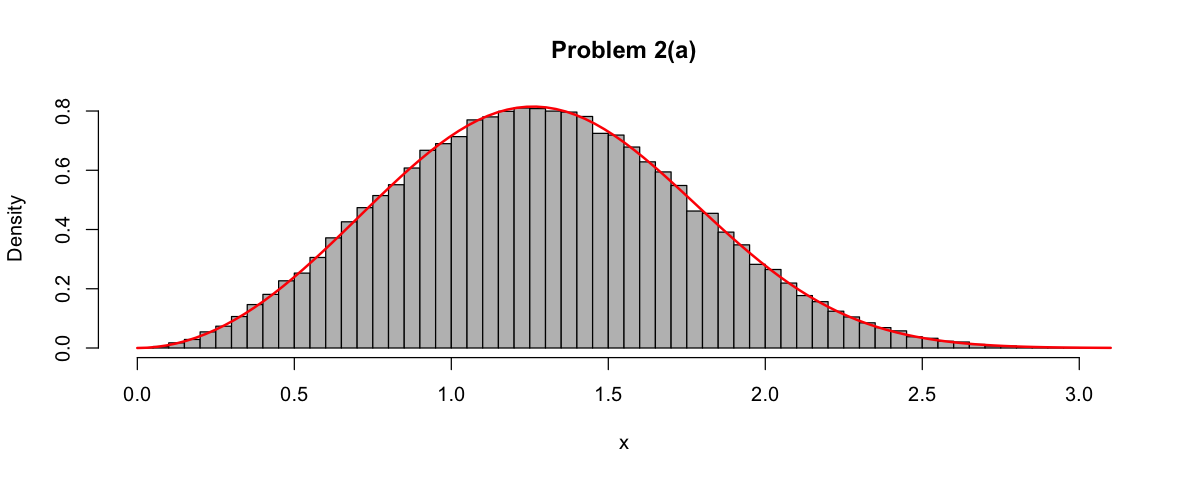

In [5]:
# F(x) = 1 - exp(-x^3/3)  =>  X = F^{-1}(U) = (-3 log(1 - U))^(1/3)
F_inv_a <- function(U) {
    X <- (-3 * log(1 - U))^(1 / 3)
    return(X)
}
rX_a <- function(n) F_inv_a(runif(n))

set.seed(1)
X_a <- rX_a(100000)
hist(X_a, breaks = 100, freq = FALSE, col = "grey", main = "Problem 2(a)", xlab = "x")
curve(x^2 * exp(-x^3 / 3), add = TRUE, col = "red", lwd = 2)

### (b) $P(N = 0) = 0.6$, $P(N = k) = C/k!$ (discrete inverse transform)

In [6]:
# sum_{k>=1} C/k! = C(e - 1) = 0.4  =>  C = 0.4 / (e - 1).
# N = smallest k with F(k) >= U; N is unbounded, so we step through k with a while loop.
C <- 0.4 / (exp(1) - 1)
F_inv_b <- function(u) {
    k <- 0
    Fk <- 0.6                       # F(0) = P(N = 0)
    while (u > Fk) {
        k <- k + 1
        Fk <- Fk + C / factorial(k) # F(k) = F(k - 1) + P(N = k)
    }
    return(k)
}
rN <- function(n) sapply(runif(n), F_inv_b)   # F_inv_b works on one u at a time

set.seed(1)
N <- rN(100000)
k <- 0:5
data.frame(k = k,
           empirical   = round(as.numeric(table(factor(N, levels = k))) / length(N), 4),
           theoretical = round(c(0.6, C / factorial(k[-1])), 4))

k,empirical,theoretical
<int>,<dbl>,<dbl>
0,0.5997,0.6000
1,0.2334,0.2328
2,0.1157,0.1164
3,0.0387,0.0388
4,0.0103,0.0097
5,0.0019,0.0019


### (c) $f_Y(y) = \frac{C}{1 + y^6}$, $y > 0$ (rejection sampling)

acceptance     theory 
 0.1637490  0.1636246

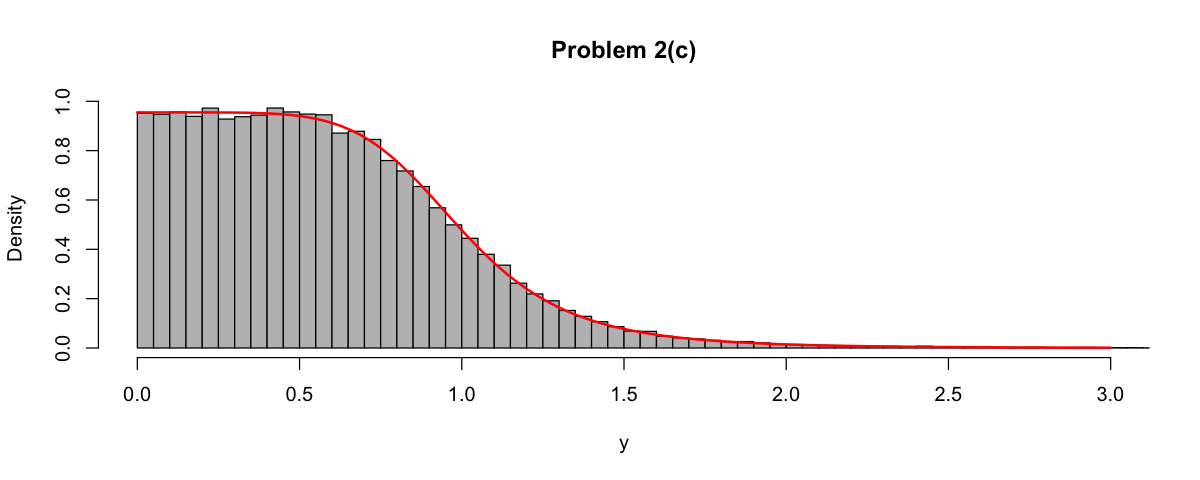

In [7]:
# Proposal g(y) = 5/(1 + y)^6 with G^{-1}(U) = (1 - U)^(-1/5) - 1.
# M = sup f*/g = 32/5 at y = 1, where f* = f without C; C cancels in the threshold f*/(M g).
g <- function(x) 5 / (1 + x)^6
f_star <- function(x) 1 / (1 + x^6)

rg <- function(n) {             # draws from g by inverse transform
    U <- runif(n)
    X <- (1 - U)^(-1 / 5) - 1
    return(X)
}
M <- 32 / 5
rY <- function(n) {
    Y <- numeric(n)
    i <- 1
    while (i <= n) {
        x <- rg(1)              # X* from g
        u <- runif(1)           # Y* from U(0, 1)
        if (u <= f_star(x) / (M * g(x))) {   # accept X*
            Y[i] <- x
            i <- i + 1
        }
    }
    return(Y)
}

set.seed(1)
Y_c <- rY(100000)
x_prop <- rg(1e6)               # acceptance rate: theory 1/(C M) with C = 3/pi
c(acceptance = mean(runif(1e6) <= f_star(x_prop) / (M * g(x_prop))), theory = pi / 3 / M)
hist(Y_c, breaks = seq(0, ceiling(max(Y_c)), by = 0.05), freq = FALSE, col = "grey",
     xlim = c(0, 3), main = "Problem 2(c)", xlab = "y")
curve(3 / pi / (1 + x^6), add = TRUE, col = "red", lwd = 2)

## Problem 3 – MLE and bootstrapping

### (a)(i) MLE of $\alpha$

In [8]:
# l(alpha) = n log(alpha) - (alpha + 1) sum(log x_i)  =>  alpha_hat = n / sum(log x_i)
x <- read_excel("MATH4515_HW2_Data1.xlsx")$X
mle_alpha <- function(data) {
    n <- length(data)
    alpha <- n / sum(log(data))
    return(alpha)
}
alpha_hat <- mle_alpha(x)
c(n = length(x), alpha_hat = alpha_hat)

n alpha_hat 
1560.0000    4.3516

### (a)(ii) Bootstrap estimate of the MSE, $B = 10\,000$

In [9]:
# MSE ≈ (1/B) sum_b (alpha*_b - alpha_hat)^2, alpha*_b = MLE on a resample of size n with replacement
set.seed(0)
B <- 10000
mle_estimates <- numeric(B)
for (i in 1:B) {
    bootstrap <- sample(x, length(x), replace = TRUE)
    mle_estimates[i] <- mle_alpha(bootstrap)
}
MSE <- mean((mle_estimates - alpha_hat)^2)
c(MSE = MSE, variance = var(mle_estimates), bias = mean(mle_estimates) - alpha_hat)

MSE   variance       bias 
0.01177734 0.01177512 0.00184125

### (b) 98% bootstrap-t confidence interval for $\mu$

n         x_mean              s 
1004.000000000    0.003167057    0.029625407

t_l       t_u 
-2.310684  2.329909

CI_lower    CI_upper 
0.000988663 0.005327476

[1] "1.78e-11"

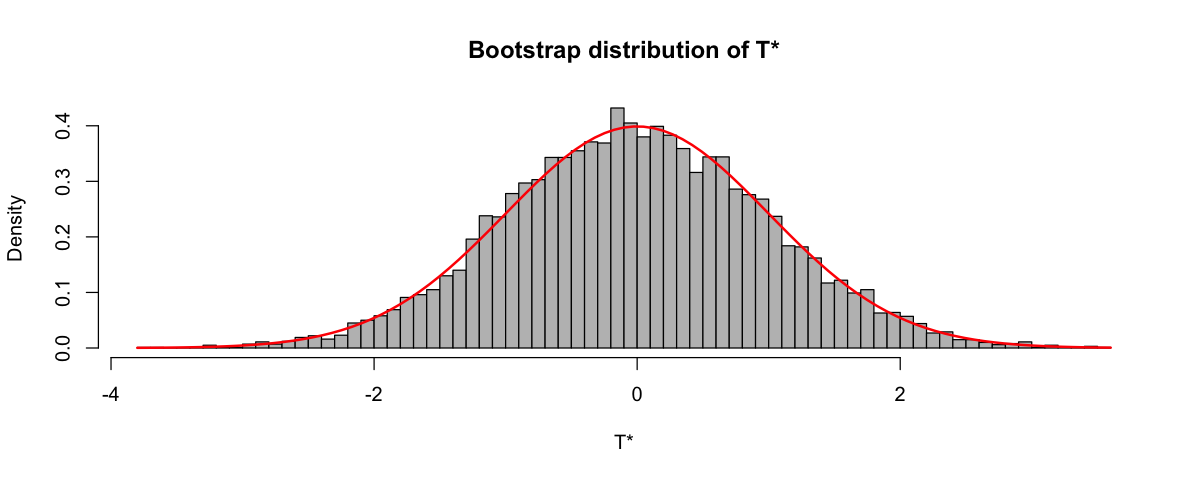

In [10]:
# Bootstrap-t: the distribution of T = (Xbar - mu)/(s/sqrt(n)) is approximated by the B values of
# T* = (Xbar* - Xbar)/(s*/sqrt(n)). With t_L, t_U the 1% and 99% quantiles of T*:
# CI = [Xbar - t_U s/sqrt(n), Xbar - t_L s/sqrt(n)]
set.seed(0)
data <- read_excel("MATH4515_HW2_Data2.xlsx")
data <- na.omit(data)          # the first day has no log-return
returns <- data$`Stock A`
B <- 10000
n <- length(returns)
t_stats <- numeric(B)
x_mean <- mean(returns)
x_std <- sd(returns)
for (i in 1:B) {
    b_sample <- sample(returns, size = n, replace = TRUE)
    b_mean <- mean(b_sample)
    b_s <- sd(b_sample)
    t_stats[i] <- (b_mean - x_mean) / (b_s / sqrt(n))
}
t_l <- unname(quantile(t_stats, 0.01))
t_u <- unname(quantile(t_stats, 0.99))
CI_mu <- c(x_mean - x_std / sqrt(n) * t_u, x_mean - x_std / sqrt(n) * t_l)
c(n = n, x_mean = x_mean, s = x_std)
c(t_l = t_l, t_u = t_u)
c(CI_lower = CI_mu[1], CI_upper = CI_mu[2])

format(shapiro.test(returns)$p.value, scientific = TRUE, digits = 3)  # normality is rejected, which motivates the bootstrap
hist(t_stats, breaks = 100, freq = FALSE, col = "grey", main = "Bootstrap distribution of T*", xlab = "T*")
curve(dt(x, df = n - 1), add = TRUE, col = "red", lwd = 2)

## Bonus Problem

### (a) $\mathbb{E}[\max(4800 - 140X - X^2, 0)]$, $X \sim N(10, 100)$

In [11]:
set.seed(0)
mu <- 10
std <- sqrt(100)
num_sim <- c(1e3, 1e4, 1e5, 1e6, 1e7)
sim_bonus <- function(n) {
    x <- rnorm(n, mean = mu, sd = std)
    pmax(4800 - 140 * x - x^2, 0)
}
mc_table(sim_bonus, num_sim)

n,estimate,SE,PE
<chr>,<dbl>,<dbl>,<chr>
"1,000",3250.47,48.8900,1.504%
"10,000",3207.81,15.4400,0.481%
"100,000",3225.63,4.8750,0.151%
"1,000,000",3226.29,1.5420,0.048%
"10,000,000",3226.61,0.4875,0.015%


### (b) Distribution of $Y = X_1 + X_2 + X_3$, $f_X(x) = Ce^{-x^4}$ (rejection sampling)

M    mean_Y    theory      sd_Y 
1.6039517 1.4669266 1.4666116 0.5450962

1%        5%       50%       95%       99% 
0.3540508 0.6085640 1.4426615 2.4057601 2.8058793

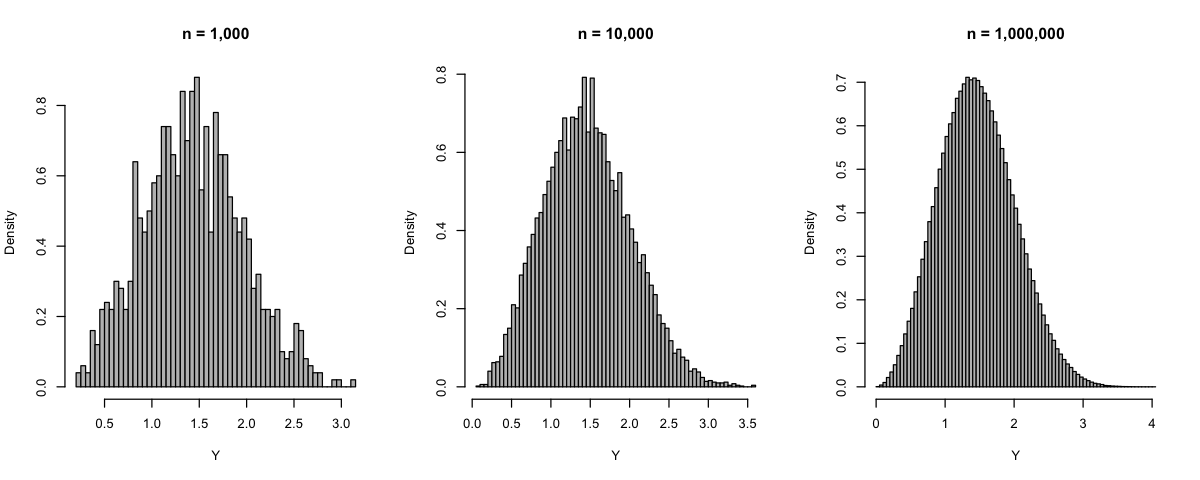

In [12]:
# Proposal g(x) = e^{-x} (Exp(1)) with G^{-1}(U) = -log(1 - U).
# f*/g = exp(x - x^4) is maximal at x0 = (1/4)^(1/3), so M = exp(x0 - x0^4) ≈ 1.604; C cancels.
rg_exp <- function(n) {
    U <- runif(n)
    X <- -log(1 - U)
    return(X)
}
f_star_x <- function(x) exp(-x^4)
g_x <- function(x) exp(-x)
x0 <- (1 / 4)^(1 / 3)
M_x <- exp(x0 - x0^4)

# Vectorised rejection: propose in batches and keep the accepted draws until we have n of them
rX <- function(n) {
    X <- numeric(0)
    while (length(X) < n) {
        x <- rg_exp(n)
        u <- runif(n)
        X <- c(X, x[u <= f_star_x(x) / (M_x * g_x(x))])
    }
    return(X[1:n])
}
rY_sum <- function(n) rowSums(matrix(rX(3 * n), ncol = 3))   # each row is (X1, X2, X3)

set.seed(0)
par(mfrow = c(1, 3))
for (n in c(1e3, 1e4, 1e6)) {
    Y <- rY_sum(n)
    hist(Y, breaks = 100, freq = FALSE, col = "grey",
         main = paste("n =", format(n, big.mark = ",", scientific = FALSE)), xlab = "Y")
}
par(mfrow = c(1, 1))

# Y now holds the n = 1,000,000 sample. Check: E[Y] = 3 E[X] = 3 Gamma(1/2) / (4 Gamma(5/4))
c(M = M_x, mean_Y = mean(Y), theory = 3 * gamma(1 / 2) / (4 * gamma(5 / 4)), sd_Y = sd(Y))
quantile(Y, c(0.01, 0.05, 0.5, 0.95, 0.99))